<a href="https://colab.research.google.com/github/lilianeuwase2/math_forML-Formative3/blob/main/bayesian_probability.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

step 1 : set up

In [1]:
import csv
import matplotlib.pyplot as plt

FILE = "IMDB Dataset.csv"
TARGET = "positive"


step 2 : reading the reviews

In [2]:
def load_reviews(path):
    reviews = []
    with open(path, encoding="utf-8") as f:
        reader = csv.DictReader(f)
        for row in reader:
            reviews.append((row["review"], row["sentiment"]))
    return reviews


reviews = load_reviews(FILE)
print("Number of reviews:", len(reviews))
print("Label of the first review:", reviews[0][1])

Number of reviews: 2418
Label of the first review: positive


step 3: cleaning

In [3]:
def clean_words(text):
    text = text.lower()
    letters_only = "".join(ch if ch.isalpha() else " " for ch in text)
    words = letters_only.split()
    return set(words)

review_words = [(clean_words(text), label) for text, label in reviews]

# showing how the review is cleaned
first_sentence = reviews[0][0].split(".")[0]
print("Before cleaning:", first_sentence)
print("After cleaning: ", sorted(clean_words(first_sentence)))

Before cleaning: One of the other reviewers has mentioned that after watching just 1 Oz episode you'll be hooked
After cleaning:  ['after', 'be', 'episode', 'has', 'hooked', 'just', 'll', 'mentioned', 'of', 'one', 'other', 'oz', 'reviewers', 'that', 'the', 'watching', 'you']


Step 4 :The Prior P counting the positive reviews

In [4]:
TOTAL = len(review_words)
N_POSITIVE = 0

for words, label in review_words:
    if label == TARGET:
        N_POSITIVE += 1

PRIOR = N_POSITIVE / TOTAL
print(f"Total reviews:    {TOTAL}")
print(f"Positive reviews: {N_POSITIVE}")
print(f"Prior P(Positive) = {N_POSITIVE}/{TOTAL} = {PRIOR:.4f}")

Total reviews:    2418
Positive reviews: 1226
Prior P(Positive) = 1226/2418 = 0.5070


Step 5: choosing keywords



we choose the words that clearly express an opinion and are common so that they are able to give reliable numbers

In [5]:
POSITIVE_KEYWORDS = ["excellent", "wonderful", "masterpiece", "loved"]
NEGATIVE_KEYWORDS = ["worst", "waste", "awful", "boring"]
ALL_KEYWORDS = POSITIVE_KEYWORDS + NEGATIVE_KEYWORDS
print("Keywords:", ALL_KEYWORDS)

Keywords: ['excellent', 'wonderful', 'masterpiece', 'loved', 'worst', 'waste', 'awful', 'boring']


step 6 : counting the keywords

---



In [6]:
n_keyword = {}   # how many reviews that has the keyword
n_both = {}      # how many reviews contain the word and are positive
for word in ALL_KEYWORDS:
    n_keyword[word] = 0
    n_both[word] = 0

for words, label in review_words:
    for word in ALL_KEYWORDS:
        if word in words:
            n_keyword[word] += 1
            if label == TARGET:
                n_both[word] += 1

for word in ALL_KEYWORDS:
    print(f"{word:<12} in {n_keyword[word]} reviews, {n_both[word]} of them positive")

excellent    in 170 reviews, 147 of them positive
wonderful    in 153 reviews, 124 of them positive
masterpiece  in 55 reviews, 45 of them positive
loved        in 129 reviews, 105 of them positive
worst        in 208 reviews, 23 of them positive
waste        in 112 reviews, 6 of them positive
awful        in 139 reviews, 14 of them positive
boring       in 142 reviews, 27 of them positive


step 7: Bayes theorem for each keyword

In [7]:
def bayes(word):
    if n_keyword[word] == 0:
        return None
    likelihood = n_both[word] / N_POSITIVE
    marginal = n_keyword[word] / TOTAL
    posterior = (likelihood * PRIOR) / marginal
    return {"keyword": word, "n_keyword": n_keyword[word], "n_both": n_both[word],
            "prior": PRIOR, "likelihood": likelihood,
            "marginal": marginal, "posterior": posterior}


def show_result(r):
    k = r["keyword"]
    print(f"Keyword: '{k}'  (in {r['n_keyword']} reviews, {r['n_both']} of them positive)")
    print(f"  Prior       P(Positive)       = {N_POSITIVE}/{TOTAL} = {r['prior']:.4f}")
    print(f"  Likelihood  P({k} | Positive) = {r['n_both']}/{N_POSITIVE} = {r['likelihood']:.4f}")
    print(f"  Marginal    P({k})            = {r['n_keyword']}/{TOTAL} = {r['marginal']:.4f}")
    print(f"  Posterior   P(Positive | {k}) = {r['likelihood']:.4f} x {r['prior']:.4f} / {r['marginal']:.4f} = {r['posterior']:.4f}")
    print()


results = []
for word in ALL_KEYWORDS:
    r = bayes(word)
    if r is None:
        print(f"'{word}' never appears in the reviews - choose another word")
    else:
        results.append(r)
        show_result(r)

Keyword: 'excellent'  (in 170 reviews, 147 of them positive)
  Prior       P(Positive)       = 1226/2418 = 0.5070
  Likelihood  P(excellent | Positive) = 147/1226 = 0.1199
  Marginal    P(excellent)            = 170/2418 = 0.0703
  Posterior   P(Positive | excellent) = 0.1199 x 0.5070 / 0.0703 = 0.8647

Keyword: 'wonderful'  (in 153 reviews, 124 of them positive)
  Prior       P(Positive)       = 1226/2418 = 0.5070
  Likelihood  P(wonderful | Positive) = 124/1226 = 0.1011
  Marginal    P(wonderful)            = 153/2418 = 0.0633
  Posterior   P(Positive | wonderful) = 0.1011 x 0.5070 / 0.0633 = 0.8105

Keyword: 'masterpiece'  (in 55 reviews, 45 of them positive)
  Prior       P(Positive)       = 1226/2418 = 0.5070
  Likelihood  P(masterpiece | Positive) = 45/1226 = 0.0367
  Marginal    P(masterpiece)            = 55/2418 = 0.0227
  Posterior   P(Positive | masterpiece) = 0.0367 x 0.5070 / 0.0227 = 0.8182

Keyword: 'loved'  (in 129 reviews, 105 of them positive)
  Prior       P(Positive

step 8 : summary table

In [8]:
print("| Keyword | Type | Prior | Likelihood | Marginal | Posterior |")
print("|---|---|---|---|---|---|")
for r in results:
    if r["keyword"] in POSITIVE_KEYWORDS:
        kind = "positive word"
    else:
        kind = "negative word"
    print(f"| {r['keyword']} | {kind} | {r['prior']:.4f} | {r['likelihood']:.4f} | {r['marginal']:.4f} | {r['posterior']:.4f} |")

| Keyword | Type | Prior | Likelihood | Marginal | Posterior |
|---|---|---|---|---|---|
| excellent | positive word | 0.5070 | 0.1199 | 0.0703 | 0.8647 |
| wonderful | positive word | 0.5070 | 0.1011 | 0.0633 | 0.8105 |
| masterpiece | positive word | 0.5070 | 0.0367 | 0.0227 | 0.8182 |
| loved | positive word | 0.5070 | 0.0856 | 0.0533 | 0.8140 |
| worst | negative word | 0.5070 | 0.0188 | 0.0860 | 0.1106 |
| waste | negative word | 0.5070 | 0.0049 | 0.0463 | 0.0536 |
| awful | negative word | 0.5070 | 0.0114 | 0.0575 | 0.1007 |
| boring | negative word | 0.5070 | 0.0220 | 0.0587 | 0.1901 |


step 9: checking that Bayes is correct

In [9]:
for r in results:
    direct = r["n_both"] / r["n_keyword"]
    print(f"{r['keyword']:<12} Bayes = {r['posterior']:.4f}   counting directly = {direct:.4f}")

excellent    Bayes = 0.8647   counting directly = 0.8647
wonderful    Bayes = 0.8105   counting directly = 0.8105
masterpiece  Bayes = 0.8182   counting directly = 0.8182
loved        Bayes = 0.8140   counting directly = 0.8140
worst        Bayes = 0.1106   counting directly = 0.1106
waste        Bayes = 0.0536   counting directly = 0.0536
awful        Bayes = 0.1007   counting directly = 0.1007
boring       Bayes = 0.1901   counting directly = 0.1901


step 10 : visualizing the results

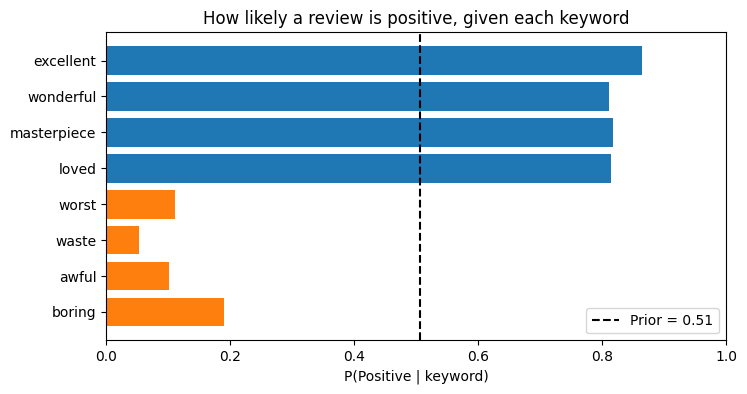

In [10]:
words = [r["keyword"] for r in results]
posteriors = [r["posterior"] for r in results]
colors = ["tab:blue" if w in POSITIVE_KEYWORDS else "tab:orange" for w in words]

plt.figure(figsize=(8, 4))
plt.barh(words, posteriors, color=colors)
plt.axvline(PRIOR, color="black", linestyle="--", label=f"Prior = {PRIOR:.2f}")
plt.xlim(0, 1)
plt.xlabel("P(Positive | keyword)")
plt.title("How likely a review is positive, given each keyword")
plt.gca().invert_yaxis()
plt.legend()
plt.show()